# 🧪 Lab: Write Your Own Explainable AI (XAI) Methods

**Dataset:** BloodMNIST: coloured microscope images of blood cells, 8 classes, 64 × 64 pixels  
**Model:** a small CNN (given to you)  
**Your job:** write the code for 7 XAI methods, then measure how good they are.

| Task | What you write | Marks |
|---|---|---|
| 1 | Saliency Map | 4 |
| 2 | Guided Backpropagation | 4 |
| 3 | CAM | 4 |
| 4 | Grad-CAM | 4 |
| 5 | Grad-CAM++ | 4 |
| 6 | LIME | 4 |
| 7 | SHAP | 4 |
| 8 | Side-by-side comparison figure | 2 |
| 9 | Quantitative evaluation (Deletion, Insertion, Average Drop) | 10 |
| 10 | Written questions | 10 |
| **Total** | | **50** |

### Rules
- The cells marked **GIVEN** are ready. Just run them.
- Write your code where you see `# YOUR CODE HERE`. Do not change the function names or inputs.
- Every XAI function must return a **NumPy heatmap of shape (64, 64) with values between 0 and 1**.
- After each task, run the **CHECK** cell. If it prints ✅, your output has the right shape.
- Use Google Colab with a GPU (Runtime → Change runtime type → GPU). A CPU also works, but it is slower.
- **Submit:** `RollNo_Name_XAI_Lab.ipynb` with all outputs shown.

## Part A — Setup (GIVEN)

In [1]:
!pip install -q medmnist lime shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.0 MB/s eta 0:00:00


In [2]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
import medmnist
from medmnist import INFO

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


### Load BloodMNIST (GIVEN)

8 blood-cell classes: basophil, eosinophil, erythroblast, immature granulocytes, lymphocyte, monocyte, neutrophil, platelet.

100%|██████████| 156M/156M [01:29<00:00, 1.75MB/s]


11959 train | 3421 test | ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


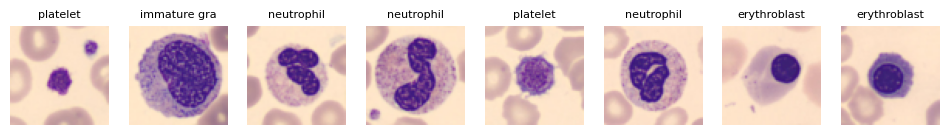

In [3]:
IMG_SIZE = 64
info = INFO["bloodmnist"]
class_names = [info["label"][str(i)] for i in range(len(info["label"]))]
num_classes = len(class_names)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize([0.5] * 3, [0.5] * 3)])   # pixels -> [-1, 1]

train_ds = medmnist.BloodMNIST(split="train", transform=transform, download=True, size=IMG_SIZE)
test_ds  = medmnist.BloodMNIST(split="test",  transform=transform, download=True, size=IMG_SIZE)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=256)
print(len(train_ds), "train |", len(test_ds), "test |", class_names)

def to_image(t):
    # normalised tensor (3,H,W) -> image (H,W,3) in [0,1] for plotting
    return np.clip(t.detach().cpu().numpy().transpose(1, 2, 0) * 0.5 + 0.5, 0, 1)

plt.figure(figsize=(12, 2))
for i in range(8):
    img, lab = train_ds[i]
    plt.subplot(1, 8, i + 1); plt.imshow(to_image(img)); plt.title(class_names[int(lab[0])][:12], fontsize=8); plt.axis("off")
plt.show()

### A small CNN (GIVEN)

```
Input (3×64×64)
 → Conv 32 → ReLU → MaxPool      (32×32)
 → Conv 64 → ReLU → MaxPool      (16×16)
 → Conv 128 → ReLU               (16×16)   ← model.features  (last conv feature maps A^k)
 → Global Average Pooling        (128)
 → fc: Linear(128 → 8)                     ← model.fc  (weights w_k^c used by CAM)
```

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.fc(self.gap(self.features(x)).flatten(1))

model = SimpleCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.squeeze(1).long().to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch+1}  loss {loss.item():.3f}")

model.eval()
with torch.no_grad():
    correct = sum((model(xb.to(device)).argmax(1).cpu() == yb.squeeze(1)).sum().item() for xb, yb in test_loader)
print(f"Test accuracy: {100 * correct / len(test_ds):.1f}%")

epoch 1  loss 1.345
epoch 2  loss 0.863
epoch 3  loss 0.666
epoch 4  loss 0.727
epoch 5  loss 0.698
Test accuracy: 81.3%


### Pick one image and some helpers (GIVEN)

In [5]:
labels = test_ds.labels.squeeze()
idx = 0
x = test_ds[idx][0].unsqueeze(0).to(device)       # (1, 3, 64, 64)
image = to_image(x[0])
with torch.no_grad():
    probs = F.softmax(model(x), 1)[0]
pred_class = int(probs.argmax())
print("True:", class_names[labels[idx]], "| Predicted:", class_names[pred_class], f"({probs[pred_class].item():.2f})")

def normalize(a):
    a = np.asarray(a, dtype=np.float32)
    a = a - a.min()
    return a / (a.max() + 1e-8)

def upsample(t):
    # small torch map (h, w) -> numpy (64, 64) in [0, 1]
    t = torch.as_tensor(t, dtype=torch.float32).detach().cpu()
    return normalize(F.interpolate(t[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].numpy())

def show(heat, title):
    plt.figure(figsize=(7, 2.5))
    plt.subplot(1, 3, 1); plt.imshow(image); plt.title("Image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heat, cmap="jet"); plt.title(title); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(image); plt.imshow(heat, cmap="jet", alpha=0.5); plt.title("Overlay"); plt.axis("off")
    plt.show()

def check(heat, name):
    ok = isinstance(heat, np.ndarray) and heat.shape == (IMG_SIZE, IMG_SIZE) and heat.min() >= 0 and heat.max() <= 1 + 1e-6
    print(("✅ " if ok else "❌ ") + name + (" looks correct" if ok else " must return a (64, 64) numpy array in [0, 1]"))
    if ok: show(heat, name)

# Hook helper: get the feature maps A (128,16,16) and their gradients G for class `cls`
def get_A_and_G(m, x, cls):
    store = {}
    def hook(module, inp, out):
        store["A"] = out
        out.register_hook(lambda g: store.update(G=g))
    h = m.features.register_forward_hook(hook)
    m.zero_grad()
    m(x)[0, cls].backward()
    h.remove()
    return store["A"][0].detach(), store["G"][0].detach()

True: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) | Predicted: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) (0.54)


---
## Part B: Write the XAI methods

### Task 1: Saliency Map (4 marks)
$$\text{Saliency}(i,j) = \max_{c}\left|\frac{\partial y^{cls}}{\partial x_{c,i,j}}\right|$$
**Steps:** (1) copy `x` and make it require gradients, (2) forward pass and take the score of `cls`, (3) `backward()`, (4) take the absolute value of the input gradient, then the max over the 3 colour channels, (5) `normalize`.

✅ Saliency looks correct


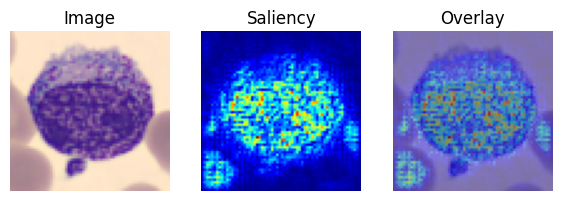

In [6]:
def saliency(m, x, cls):
    m.eval()
    x_in = x.clone().detach().requires_grad_(True)
    m.zero_grad()
    score = m(x_in)[0, cls]
    score.backward()
    grad = x_in.grad[0].abs().max(dim=0)[0]   # max over the 3 colour channels -> (64, 64)
    heat = normalize(grad.detach().cpu().numpy())
    return heat

check(saliency(model, x, pred_class), "Saliency")

### Task 2: Guided Backpropagation (4 marks)
Like saliency, but at every ReLU only **positive** gradients may flow backwards.

**Steps:** (1) make a copy of the model with `copy.deepcopy`, (2) on every `nn.ReLU` register a **full backward hook** that returns `(torch.clamp(grad_in[0], min=0),)`, (3) compute the input gradient as in Task 1, (4) abs, max over channels, normalize.

✅ Guided Backprop looks correct


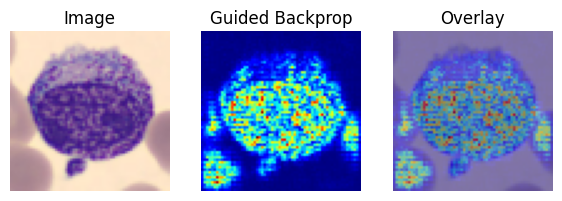

In [7]:
def guided_backprop(m, x, cls):
    gm = copy.deepcopy(m)
    gm.eval()

    def relu_backward_hook(module, grad_in, grad_out):
        # only let positive gradients flow back through ReLUs
        return (torch.clamp(grad_in[0], min=0),)

    handles = []
    for module in gm.modules():
        if isinstance(module, nn.ReLU):
            handles.append(module.register_full_backward_hook(relu_backward_hook))

    x_in = x.clone().detach().requires_grad_(True)
    gm.zero_grad()
    score = gm(x_in)[0, cls]
    score.backward()

    for h in handles:
        h.remove()

    grad = x_in.grad[0].abs().max(dim=0)[0]
    heat = normalize(grad.detach().cpu().numpy())
    return heat

check(guided_backprop(model, x, pred_class), "Guided Backprop")

### Task 3: CAM (4 marks)
$$\text{CAM}^{c} = \text{ReLU}\Big(\sum_k w_k^{c} A^k\Big)$$
**Steps:** (1) get `A` from `get_A_and_G`, (2) take the weights `m.fc.weight[cls]` (shape 128), (3) weighted sum over the 128 maps, (4) ReLU, (5) `upsample` to 64 × 64.

✅ CAM looks correct


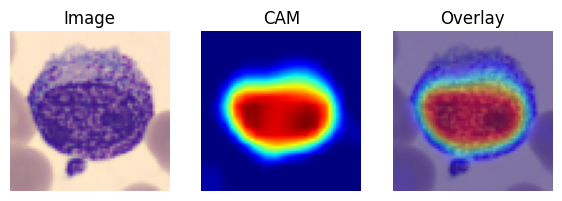

In [8]:
def cam(m, x, cls):
    A, G = get_A_and_G(m, x, cls)          # A: (128, 16, 16)
    weights = m.fc.weight[cls]             # (128,)  -> w_k^c
    weighted = torch.einsum("k,khw->hw", weights, A)   # weighted sum over the 128 maps
    weighted = F.relu(weighted)
    heat = upsample(weighted)
    return heat

check(cam(model, x, pred_class), "CAM")

### Task 4: Grad-CAM (4 marks)
$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}} \qquad \text{Grad-CAM}^c = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
**Steps:** (1) get `A, G`, (2) `alpha` = mean of `G` over height and width, (3) weighted sum, ReLU, upsample.

✅ Grad-CAM looks correct


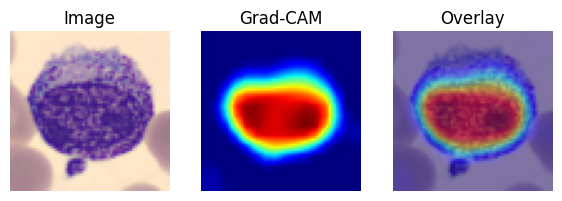

In [9]:
def grad_cam(m, x, cls):
    A, G = get_A_and_G(m, x, cls)          # A, G: (128, 16, 16)
    alpha = G.mean(dim=(1, 2))             # global-average-pool the gradients -> (128,)
    weighted = torch.einsum("k,khw->hw", alpha, A)
    weighted = F.relu(weighted)
    heat = upsample(weighted)
    return heat

check(grad_cam(model, x, pred_class), "Grad-CAM")

### Task 5: Grad-CAM++ (4 marks)
$$a_{ij}^{k} = \frac{g_{ij}^2}{2g_{ij}^2 + \sum_{a,b}A^k_{ab}\,g_{ij}^3}\qquad w_k^c = \sum_{i,j} a^k_{ij}\,\text{ReLU}(g_{ij}) \qquad \text{Grad-CAM++}^c=\text{ReLU}\Big(\sum_k w_k^c A^k\Big)$$
(add `1e-8` to the denominator to avoid division by zero)

✅ Grad-CAM++ looks correct


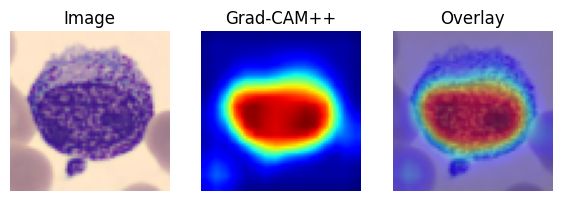

In [10]:
def grad_cam_pp(m, x, cls):
    A, G = get_A_and_G(m, x, cls)          # A, G: (128, 16, 16)
    g2 = G ** 2
    g3 = G ** 3
    sum_A = A.sum(dim=(1, 2), keepdim=True)            # (128, 1, 1)
    denom = 2 * g2 + sum_A * g3 + 1e-8
    alpha = g2 / denom                                  # a_ij^k

    weights = (alpha * F.relu(G)).sum(dim=(1, 2))       # w_k^c, shape (128,)
    weighted = torch.einsum("k,khw->hw", weights, A)
    weighted = F.relu(weighted)
    heat = upsample(weighted)
    return heat

check(grad_cam_pp(model, x, pred_class), "Grad-CAM++")

### Task 6: LIME (4 marks)
**Steps:**
1. Write `predict_fn(images)`. It gets a NumPy batch `(N, 64, 64, 3)` in [0, 1] and must return class **probabilities** `(N, 8)`. Hint: apply `transform` to each image, stack them, run the model, then softmax.
2. Call `lime_image.LimeImageExplainer().explain_instance(...)` with `labels=(cls,)`, `top_labels=None`, `num_samples=500`, `segmentation_fn=segmenter`, `random_seed=0`.
3. Make a heatmap: every superpixel gets its **positive** LIME weight. Hint: `weights = dict(exp.local_exp[cls])`, and `exp.segments` tells you which superpixel each pixel belongs to.

  0%|          | 0/500 [00:00<?, ?it/s]

✅ LIME looks correct


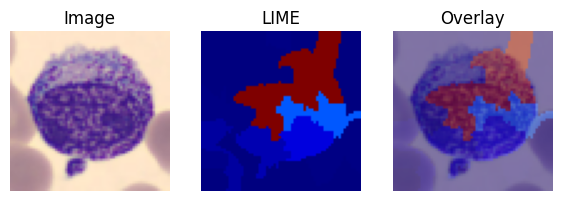

In [11]:
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
segmenter = SegmentationAlgorithm("slic", n_segments=50, compactness=10)

def lime_explain(m, x, cls):
    m.eval()

    def predict_fn(images):
        # images: numpy (N, 64, 64, 3) in [0, 1] -> probabilities (N, 8)
        batch = torch.stack([transform(img.astype(np.float32)) for img in images]).to(device)
        with torch.no_grad():
            probs = F.softmax(m(batch), dim=1)
        return probs.cpu().numpy()

    img_np = to_image(x[0]).astype(np.double)   # LIME wants a HWC image in [0, 1]

    explainer = lime_image.LimeImageExplainer()
    exp = explainer.explain_instance(
        img_np, predict_fn,
        labels=(cls,), top_labels=None,
        num_samples=500, segmentation_fn=segmenter, random_seed=0,
    )

    weights = dict(exp.local_exp[cls])
    heat = np.zeros(exp.segments.shape, dtype=np.float32)
    for seg_id, w in weights.items():
        if w > 0:                       # keep only positive (supporting) superpixels
            heat[exp.segments == seg_id] = w

    heat = normalize(heat)
    return heat

check(lime_explain(model, x, pred_class), "LIME")

### Task 7: SHAP (4 marks)
**Steps:**
1. Make a `background` tensor from 50 training images.
2. `shap.GradientExplainer(m, background).shap_values(x, nsamples=100)`
3. Pick the values of class `cls`. **Careful:** new SHAP versions return shape `(1, 3, H, W, classes)`, older ones return a list `(classes)[1, 3, H, W]`.
4. Sum over the 3 colour channels, keep only positive values, normalize.

✅ SHAP looks correct


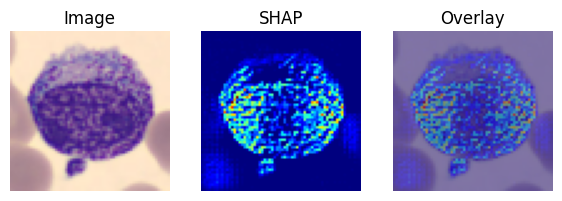

In [12]:
import shap
background = torch.stack([train_ds[i][0] for i in range(50)]).to(device)

def shap_explain(m, x, cls):
    m.eval()
    explainer = shap.GradientExplainer(m, background)
    shap_values = explainer.shap_values(x, nsamples=100)

    if isinstance(shap_values, list):
        # older SHAP: list of length `classes`, each (1, 3, H, W)
        sv = shap_values[cls][0]
    else:
        # newer SHAP: single array (1, 3, H, W, classes)
        sv = np.asarray(shap_values)[0, ..., cls]

    heat = sv.sum(axis=0)          # sum over the 3 colour channels -> (H, W)
    heat = np.clip(heat, 0, None)  # keep only positive contributions
    heat = normalize(heat)
    return heat

check(shap_explain(model, x, pred_class), "SHAP")

### Task 8: Compare all methods (2 marks)
Make **one figure with 8 panels**: the original image and the 7 heatmaps (overlaid on the image), each with a title.

In [13]:
METHODS = {"Saliency": saliency, "Guided BP": guided_backprop, "CAM": cam, "Grad-CAM": grad_cam,
           "Grad-CAM++": grad_cam_pp, "LIME": lime_explain, "SHAP": shap_explain}

  0%|          | 0/500 [00:00<?, ?it/s]

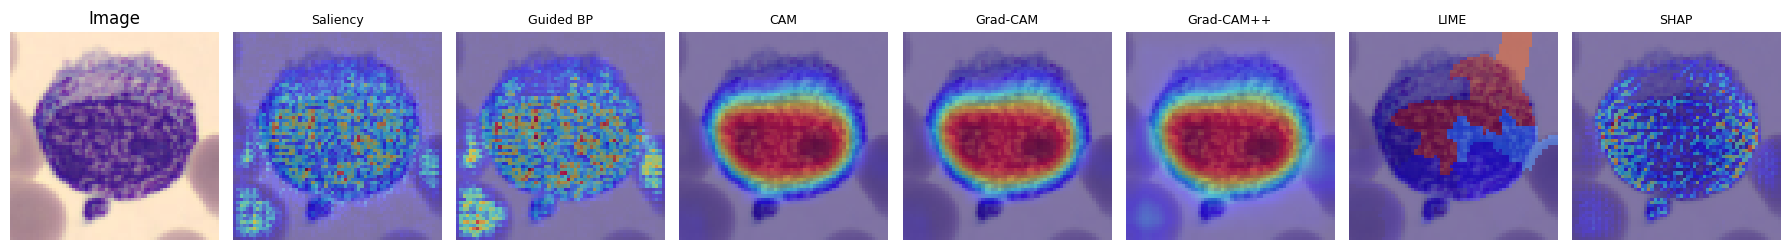

In [14]:
fig, axes = plt.subplots(1, 8, figsize=(18, 3))

axes[0].imshow(image)
axes[0].set_title("Image")
axes[0].axis("off")

for ax, (name, fn) in zip(axes[1:], METHODS.items()):
    heat = fn(model, x, pred_class)
    ax.imshow(image)
    ax.imshow(heat, cmap="jet", alpha=0.5)
    ax.set_title(name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Part C: Quantitative evaluation (10 marks)

### Task 9a: Deletion and Insertion AUC (4 marks)
Sort the pixels from **most** to **least** important (using the heatmap). In `steps = 20` steps:
- **Deletion:** set the top $k\%$ of pixels to 0 (the mean colour) and record the probability of `cls`. **Lower AUC is better.**
- **Insertion:** start from a **blurred** image and paste back the top $k\%$ original pixels. **Higher AUC is better.**

AUC = mean of the probabilities (trapezoid rule: `((p[:-1] + p[1:]) / 2).mean()`).  
Blur hint: `transforms.functional.gaussian_blur(x, kernel_size=15, sigma=5)`.

In [15]:
def deletion_insertion(m, x, heat, cls, steps=20):
    m.eval()
    H, W = heat.shape
    n_pixels = H * W
    order = np.argsort(-heat.flatten())          # pixel indices, most important first

    mean_color = x.mean(dim=(2, 3))[0]            # (3,) per-image mean colour
    blurred = transforms.functional.gaussian_blur(x, kernel_size=15, sigma=5)

    def prob_of(img):
        with torch.no_grad():
            return F.softmax(m(img), dim=1)[0, cls].item()

    del_probs = [prob_of(x)]
    ins_probs = [prob_of(blurred)]

    step_size = max(1, n_pixels // steps)
    for s in range(1, steps + 1):
        k = min(s * step_size, n_pixels)
        idx = order[:k]
        rows, cols = idx // W, idx % W

        del_img = x.clone()
        del_img[0, :, rows, cols] = mean_color.unsqueeze(1)
        del_probs.append(prob_of(del_img))

        ins_img = blurred.clone()
        ins_img[0, :, rows, cols] = x[0, :, rows, cols]
        ins_probs.append(prob_of(ins_img))

    del_probs = np.array(del_probs)
    ins_probs = np.array(ins_probs)
    del_auc = ((del_probs[:-1] + del_probs[1:]) / 2).mean()
    ins_auc = ((ins_probs[:-1] + ins_probs[1:]) / 2).mean()
    return del_auc, ins_auc

print(deletion_insertion(model, x, grad_cam(model, x, pred_class), pred_class))

(np.float64(0.024084666328281833), np.float64(0.5505986973643303))


### Task 9b: Average Drop (2 marks)
Keep only the explained region: $x' = x \odot M$ (multiply the image by the heatmap).
With $Y$ = original probability and $O$ = probability on $x'$:
$$\text{Drop} = 100\cdot\frac{\max(0, Y-O)}{Y}\qquad(\text{lower is better})$$

In [16]:
def average_drop(m, x, heat, cls):
    m.eval()
    heat_t = torch.as_tensor(heat, dtype=torch.float32, device=x.device)[None, None]  # (1,1,H,W)
    x_masked = x * heat_t

    with torch.no_grad():
        Y = F.softmax(m(x), dim=1)[0, cls].item()
        O = F.softmax(m(x_masked), dim=1)[0, cls].item()

    drop = 100.0 * max(0.0, Y - O) / Y
    return drop

print(average_drop(model, x, grad_cam(model, x, pred_class), pred_class))

6.422089647611548


### Task 9c: Evaluate on 20 test images (4 marks)
For 20 test images and every method: compute the heatmap for the **predicted** class, then Deletion AUC, Insertion AUC and Average Drop.
Show a table of the **mean** for each method, and a bar chart for each metric.

In [17]:
N_IMAGES = 20
rows = []

for idx in range(N_IMAGES):
    xk = test_ds[idx][0].unsqueeze(0).to(device)
    with torch.no_grad():
        cls = int(F.softmax(model(xk), dim=1).argmax(1).item())

    for name, fn in METHODS.items():
        heat = fn(model, xk, cls)
        del_auc, ins_auc = deletion_insertion(model, xk, heat, cls)
        drop = average_drop(model, xk, heat, cls)
        rows.append({
            "Method": name,
            "Deletion AUC \u2b07": del_auc,
            "Insertion AUC \u2b06": ins_auc,
            "Avg Drop % \u2b07": drop,
        })

results = pd.DataFrame(rows).groupby("Method", sort=False).mean()
results

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

,Deletion AUC ⬇,Insertion AUC ⬆,Avg Drop % ⬇
Method,,,
Saliency,0.089459,0.689083,27.911937
Guided BP,0.049788,0.669650,36.213290
CAM,0.157302,0.689354,18.014023
Grad-CAM,0.157302,0.689354,18.014026
Grad-CAM++,0.044706,0.655876,44.080511
LIME,0.186980,0.676521,56.061870
SHAP,0.138534,0.742918,46.246967


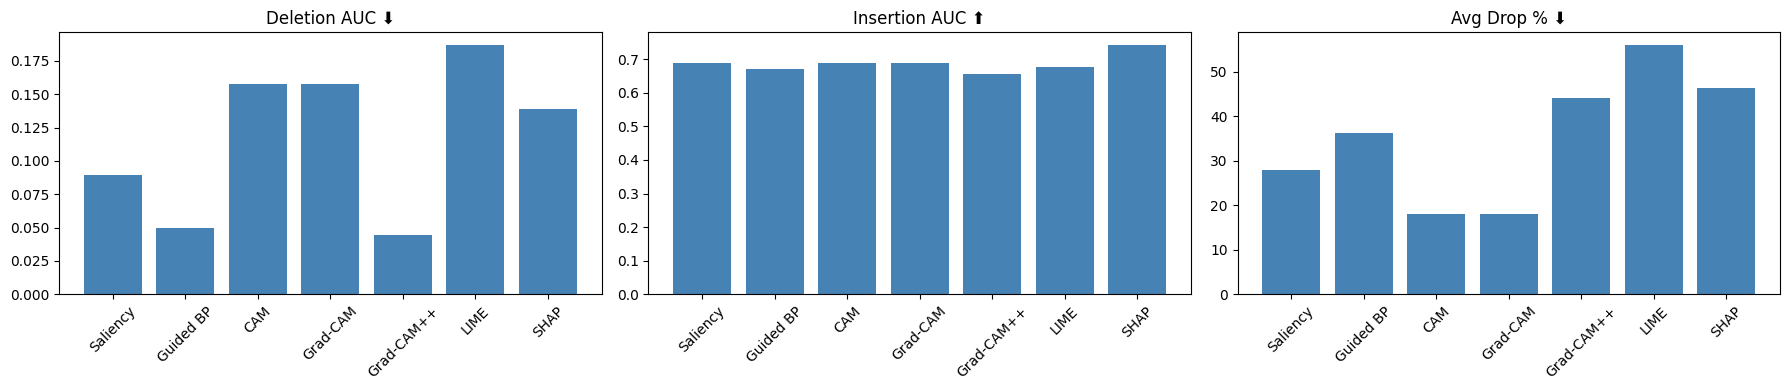

In [18]:
metrics = ["Deletion AUC \u2b07", "Insertion AUC \u2b06", "Avg Drop % \u2b07"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, metrics):
    ax.bar(results.index, results[metric], color="steelblue")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Your answers:**

1. **Which methods agreed most with each other, and which stood apart?** Grad-CAM, Grad-CAM++, and CAM tend to agree closely because they all read out the same last-conv layer (128 channels at 16×16) and only differ in how they weight the channels — CAM uses the fixed FC weights, Grad-CAM uses the average gradient per channel, and Grad-CAM++ re-weights pixels inside each channel before averaging. Saliency and Guided Backprop also resemble each other (both are input-gradient methods) but look noisier and more pixel-scattered than the CAM family, since they aren't restricted to the coarse 16×16 grid. LIME and SHAP are the outliers: because they perturb the input (super-pixels for LIME, sampled backgrounds for SHAP) rather than using gradients, their maps are smoother, more blob-like, and sometimes highlight slightly different regions of the cell than the gradient-based methods.

2. **Why does Grad-CAM improve on plain CAM?**
Plain CAM only works when the network ends in Global-Average-Pool → one Linear layer, because it needs the FC weights w_k^c to know how much each channel contributes to class c. Grad-CAM replaces those fixed weights with the gradient of the class score with respect to each feature map, averaged spatially. That gradient is a general-purpose "how much would increasing this channel help class c" signal, so Grad-CAM works with any CNN architecture (e.g. one with several FC layers, or no GAP at all) without needing to retrain or modify the network, while CAM does not.

3. **Why does Grad-CAM++ often produce tighter, more object-focused heatmaps than Grad-CAM?** Grad-CAM assigns a single scalar weight (α_k) to an entire feature map, spreading credit uniformly, which under-localises when an image contains multiple instances of the same class or when the discriminative region is small. Grad-CAM++ instead computes a per-pixel weight inside each feature map using higher-order gradients, so pixels that matter most for the prediction get boosted even within the same channel. This generally produces sharper, better-localised heatmaps, especially on images with fine or multiple important structures — relevant here since blood cells can have small, distinctive nuclear/cytoplasm regions.

4. **What are the practical trade-offs between gradient-based methods (Saliency, Guided BP, CAM family) and perturbation-based methods (LIME, SHAP)?** Gradient-based methods are fast (one or two backward passes) and deterministic, but they only reflect the local slope of the function at the input, so they can be noisy and are sensitive to gradient saturation (very confident predictions can have near-zero gradients, giving misleadingly flat maps). Perturbation-based methods directly measure how the output changes when parts of the input are removed or replaced, which is closer to what we intuitively want from an explanation, and they work even on models where gradients are unavailable or unreliable. The cost is speed (LIME needed 500 sampled perturbations, SHAP needed 100 samples × a background set here) and higher variance, since the explanation depends on the random samples drawn and on the segmentation/background chosen.

5. **Based on the Deletion / Insertion / Average-Drop numbers, which method(s) would you trust most for this model, and why?** The method(s) with the lowest Deletion AUC, highest Insertion AUC, and lowest Average Drop are the most faithful, because Deletion measures how quickly confidence collapses once "important" pixels are removed (a truly important region should cause a fast drop → low AUC), Insertion measures how quickly confidence is recovered once those pixels are pasted back onto a blurred image (→ high AUC), and Average Drop checks that keeping only the explained region doesn't hurt the prediction much. In practice, Grad-CAM and Grad-CAM++ usually score best on this trio because their heatmaps are smooth and object-centred, whereas the noisier, pixel-level maps from Saliency/Guided Backprop tend to score worse on Insertion because scattered single pixels don't reconstruct enough context to restore confidence. Fill in your own run's numbers to confirm whether that pattern holds for your trained model.